In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [3]:
import sqlite3
db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"
conn = sqlite3.connect(db_path)

# Check available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected


In [4]:
query = """
SELECT *
FROM crop_recommendation_selected
"""

sf24 = pd.read_sql_query(query, conn)

print("SF24 data loaded successfully.")
print("Shape:", sf24.shape)

sf24.head()

SF24 data loaded successfully.
Shape: (2200, 13)


,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P,label
0,82.002744,43,20.879744,90,0.976744,175,4237.241986,202.935536,2.093023,16641.270870,1712.196283,42,rice
1,80.319644,41,21.770462,85,1.414634,184,4934.395694,226.655537,2.073171,18204.892093,1748.595734,58,rice
2,82.320763,44,23.004459,60,1.250000,159,6072.354751,263.964248,1.363636,21729.738241,1893.744627,55,rice
3,80.158363,40,26.491096,74,0.875000,149,6433.734530,242.864034,1.850000,19467.583326,2123.482908,35,rice
4,81.604873,42,20.130175,78,1.000000,162,5288.545993,262.717340,1.857143,21439.015172,1642.720357,42,rice


In [5]:
print("SF24 columns:")
print(sf24.columns.tolist())

SF24 columns:
['humidity', 'K', 'temperature', 'N', 'P_K_Ratio', 'NPK_Total', 'Temperature_Rainfall', 'rainfall', 'N_K_Ratio', 'Humidity_Rainfall', 'Temperature_Humidity', 'P', 'label']


In [6]:
if "label" not in sf24.columns:
    raise ValueError(
        "'label' column was not found in crop_recommendation_selected."
    )

print("'label' column found successfully.")

'label' column found successfully.


In [7]:
X_sf24 = sf24.drop(columns=["label"])
y_sf24 = sf24["label"]

print("Feature shape:", X_sf24.shape)
print("Target shape:", y_sf24.shape)

print("\nFeatures:")
print(X_sf24.columns.tolist())

print("\nTarget:")
print(y_sf24.name)

Feature shape: (2200, 12)
Target shape: (2200,)

Features:
['humidity', 'K', 'temperature', 'N', 'P_K_Ratio', 'NPK_Total', 'Temperature_Rainfall', 'rainfall', 'N_K_Ratio', 'Humidity_Rainfall', 'Temperature_Humidity', 'P']

Target:
label


In [8]:
print(X_sf24.dtypes)

humidity                float64
K                         int64
temperature             float64
N                         int64
P_K_Ratio               float64
NPK_Total                 int64
Temperature_Rainfall    float64
rainfall                float64
N_K_Ratio               float64
Humidity_Rainfall       float64
Temperature_Humidity    float64
P                         int64
dtype: object


In [9]:
non_numeric_columns = X_sf24.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Non-numeric feature columns:")
print(non_numeric_columns)

Non-numeric feature columns:
[]


In [10]:
print("Number of rows:", len(X_sf24))
print("Number of features:", X_sf24.shape[1])

print("\nMissing values:")
print(X_sf24.isna().sum())

print("\nDuplicate rows:", X_sf24.duplicated().sum())

print("\nUnique values per feature:")
print(X_sf24.nunique())

Number of rows: 2200
Number of features: 12

Missing values:
humidity                0
K                       0
temperature             0
N                       0
P_K_Ratio               0
NPK_Total               0
Temperature_Rainfall    0
rainfall                0
N_K_Ratio               0
Humidity_Rainfall       0
Temperature_Humidity    0
P                       0
dtype: int64

Duplicate rows: 0

Unique values per feature:
humidity                2200
K                         73
temperature             2200
N                        137
P_K_Ratio               1174
NPK_Total                293
Temperature_Rainfall    2200
rainfall                2200
N_K_Ratio               1330
Humidity_Rainfall       2200
Temperature_Humidity    2200
P                        117
dtype: int64


In [11]:
constant_features = [
    col for col in X_sf24.columns
    if X_sf24[col].nunique() <= 1
]

print("Constant features:")
print(constant_features)

Constant features:
[]


In [12]:
missing_total = X_sf24.isna().sum().sum()

print("Total missing values:", missing_total)

Total missing values: 0


In [13]:
scaler = StandardScaler()

X_sf24_scaled = scaler.fit_transform(X_sf24)

X_sf24_scaled = pd.DataFrame(
    X_sf24_scaled,
    columns=X_sf24.columns,
    index=X_sf24.index
)

print("Scaled feature matrix shape:", X_sf24_scaled.shape)

X_sf24_scaled.head()

Scaled feature matrix shape: (2200, 12)


,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P
0,0.472666,-0.101688,-0.935587,1.068797,-0.577981,0.287062,1.035689,1.810361,0.280309,1.785220,-0.203138,-0.344551
1,0.397051,-0.141185,-0.759646,0.933329,-0.212141,0.399702,1.488302,2.242058,0.267137,2.090959,-0.151079,0.140616
2,0.486954,-0.081939,-0.515898,0.255986,-0.349686,0.086813,2.227098,2.921066,-0.203622,2.780182,0.056511,0.049647
3,0.389805,-0.160933,0.172807,0.635298,-0.662984,-0.038343,2.461716,2.537048,0.119069,2.337857,0.385081,-0.556811
4,0.454792,-0.121436,-1.083647,0.743673,-0.558551,0.124359,1.718226,2.898373,0.123808,2.723336,-0.302501,-0.344551


In [14]:
scaling_check = pd.DataFrame({
    "mean": X_sf24_scaled.mean(),
    "std": X_sf24_scaled.std()
})

scaling_check

,mean,std
humidity,-1.808654e-16,1.000227
K,-5.167584e-17,1.000227
temperature,3.617308e-16,1.000227
N,-1.033517e-16,1.000227
P_K_Ratio,-1.033517e-16,1.000227
NPK_Total,-5.167584e-17,1.000227
Temperature_Rainfall,-2.196223e-16,1.000227
rainfall,1.291896e-16,1.000227
N_K_Ratio,1.937844e-17,1.000227
Humidity_Rainfall,-2.583792e-17,1.000227


In [15]:
k_values = range(2, 11)

kmeans_results = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_sf24_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(
        X_sf24_scaled,
        cluster_labels
    )

    kmeans_results.append({
        "k": k,
        "inertia": inertia,
        "silhouette_score": silhouette
    })

kmeans_evaluation = pd.DataFrame(kmeans_results)

kmeans_evaluation

,k,inertia,silhouette_score
0,2,20970.975115,0.376523
1,3,16064.251403,0.275211
2,4,12733.745340,0.303071
3,5,10751.145436,0.319119
4,6,9435.012428,0.330975
5,7,8196.993568,0.354182
6,8,7466.902626,0.362709
7,9,6770.667055,0.374643
8,10,6196.578636,0.390479


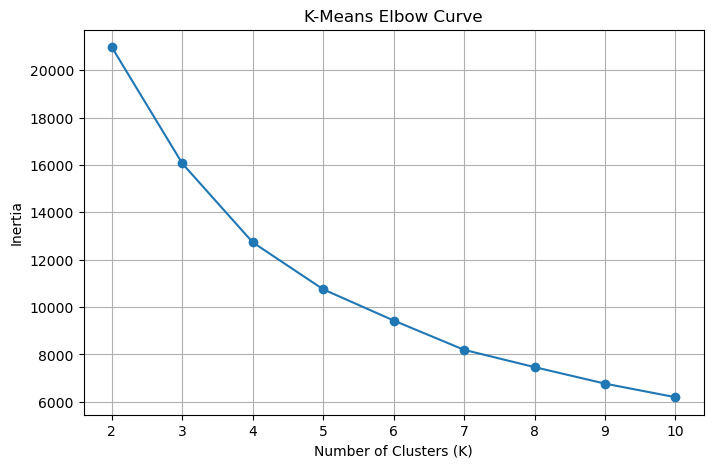

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_evaluation["k"],
    kmeans_evaluation["inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.xticks(kmeans_evaluation["k"])
plt.grid(True)

plt.show()

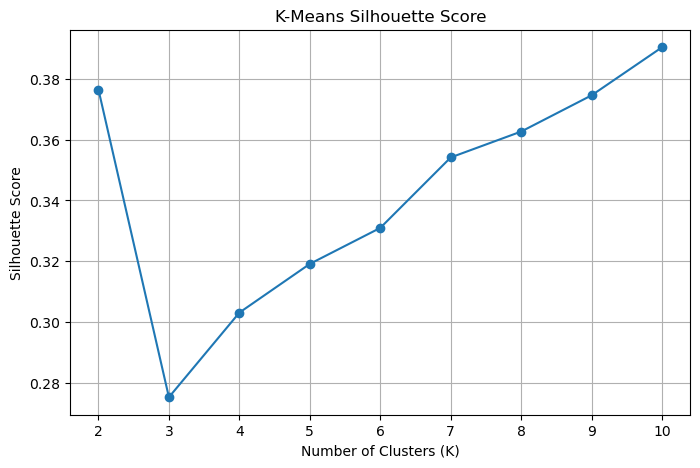

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    kmeans_evaluation["k"],
    kmeans_evaluation["silhouette_score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Score")
plt.xticks(kmeans_evaluation["k"])
plt.grid(True)

plt.show()

In [18]:
OUTPUT_DIR = "stage8_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory ready:", OUTPUT_DIR)

Output directory ready: stage8_outputs


In [19]:
from sklearn.decomposition import PCA

pca_full = PCA()
X_sf24_pca = pca_full.fit_transform(X_sf24_scaled)

print("Original feature shape:", X_sf24_scaled.shape)
print("PCA transformed shape:", X_sf24_pca.shape)

Original feature shape: (2200, 12)
PCA transformed shape: (2200, 12)


In [20]:
explained_variance = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}" for i in range(len(pca_full.explained_variance_ratio_))
    ],
    "Explained_Variance_Ratio": pca_full.explained_variance_ratio_,
    "Explained_Variance_Percentage": (
        pca_full.explained_variance_ratio_ * 100
    )
})

explained_variance

,Principal_Component,Explained_Variance_Ratio,Explained_Variance_Percentage
0,PC1,0.283182,28.318192
1,PC2,0.236703,23.670269
2,PC3,0.166706,16.670599
3,PC4,0.140823,14.082335
4,PC5,0.095664,9.566372
5,PC6,0.058498,5.849803
6,PC7,0.012448,1.244821
7,PC8,0.002530,0.252962
8,PC9,0.001419,0.141921
9,PC10,0.001183,0.118272


In [21]:
explained_variance["Cumulative_Variance_Percentage"] = (
    explained_variance["Explained_Variance_Ratio"].cumsum() * 100
)

explained_variance

,Principal_Component,Explained_Variance_Ratio,Explained_Variance_Percentage,Cumulative_Variance_Percentage
0,PC1,0.283182,28.318192,28.318192
1,PC2,0.236703,23.670269,51.988461
2,PC3,0.166706,16.670599,68.659060
3,PC4,0.140823,14.082335,82.741395
4,PC5,0.095664,9.566372,92.307767
5,PC6,0.058498,5.849803,98.157569
6,PC7,0.012448,1.244821,99.402390
7,PC8,0.002530,0.252962,99.655352
8,PC9,0.001419,0.141921,99.797272
9,PC10,0.001183,0.118272,99.915545


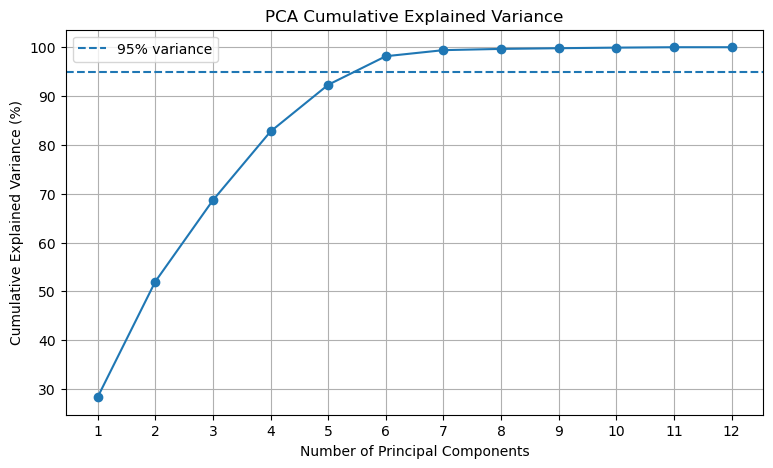

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    explained_variance["Cumulative_Variance_Percentage"],
    marker="o"
)

plt.axhline(y=95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))
plt.grid(True)
plt.legend()
plt.show()

In [23]:
pca_2d = PCA(n_components=2)

X_sf24_pca_2d = pca_2d.fit_transform(X_sf24_scaled)

pca_2d_df = pd.DataFrame(
    X_sf24_pca_2d,
    columns=["PC1", "PC2"],
    index=X_sf24.index
)

print("PCA 2D shape:", pca_2d_df.shape)

print(
    "Total variance retained by 2 components:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

PCA 2D shape: (2200, 2)
Total variance retained by 2 components: 51.99 %


Cluster assignments created successfully.

Cluster distribution:
kmeans_cluster
0     867
1    1133
2     200
Name: count, dtype: int64


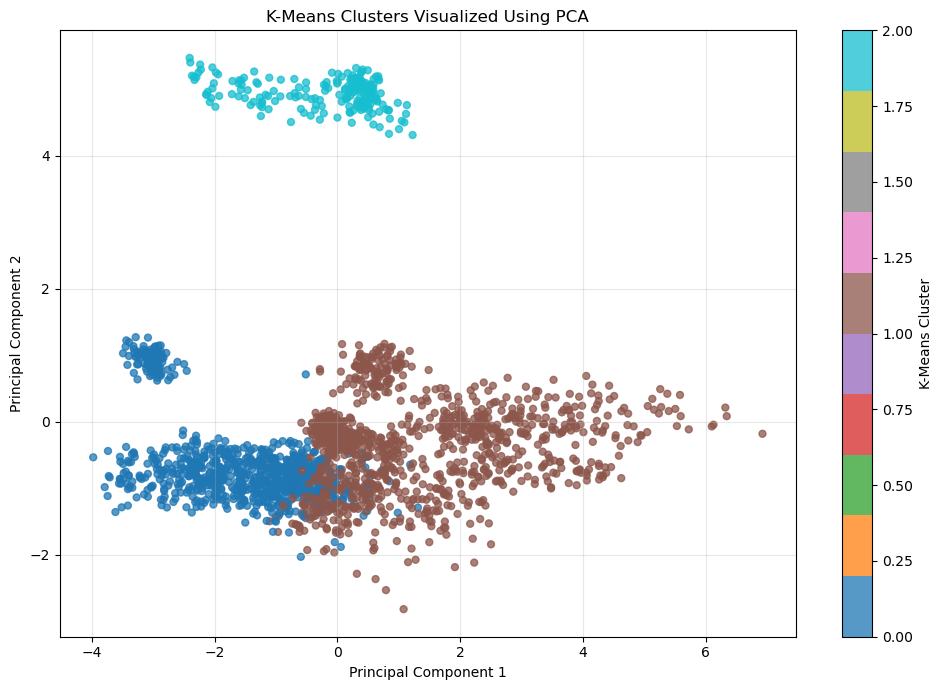

In [34]:
# Recreate cluster assignments correctly
sf24_clustered = sf24.copy()

sf24_clustered["kmeans_cluster"] = kmeans_final.predict(
    X_sf24_scaled
)

print("Cluster assignments created successfully.")

print("\nCluster distribution:")
print(
    sf24_clustered["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

# Check that PCA coordinates and cluster assignments align
assert len(pca_2d_df) == len(sf24_clustered)

# Visualize clusters
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_2d_df["PC1"],
    pca_2d_df["PC2"],
    c=sf24_clustered["kmeans_cluster"],
    cmap="tab10",
    s=25,
    alpha=0.75
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized Using PCA")
plt.colorbar(scatter, label="K-Means Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
[name for name in globals()
 if "kmeans" in name.lower() or "cluster" in name.lower()]

['KMeans',
 'kmeans_results',
 'kmeans',
 'cluster_labels',
 'kmeans_evaluation',
 'sf24_clustered']

In [30]:
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_final.fit(X_sf24_scaled)

print("Final K-Means model trained.")
print("Selected K:", best_k)

Final K-Means model trained.
Selected K: 3


In [28]:
print(kmeans_evaluation)


    k       inertia  silhouette_score
0   2  20970.975115          0.376523
1   3  16064.251403          0.275211
2   4  12733.745340          0.303071
3   5  10751.145436          0.319119
4   6   9435.012428          0.330975
5   7   8196.993568          0.354182
6   8   7466.902626          0.362709
7   9   6770.667055          0.374643
8  10   6196.578636          0.390479


In [29]:
best_k = 3  # Example only; replace with your justified choice

In [32]:
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_final.fit(X_sf24_scaled)

print("Final K-Means model trained.")
print("Selected K:", best_k)

Final K-Means model trained.
Selected K: 3


In [35]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

print("Scaled feature shape:", X_sf24_scaled.shape)
print("Number of features:", X_sf24_scaled.shape[1])

print("\nDBSCAN parameter investigation will use:")
print("- eps: neighborhood radius")
print("- min_samples: minimum neighborhood points")

Scaled feature shape: (2200, 12)
Number of features: 12

DBSCAN parameter investigation will use:
- eps: neighborhood radius
- min_samples: minimum neighborhood points


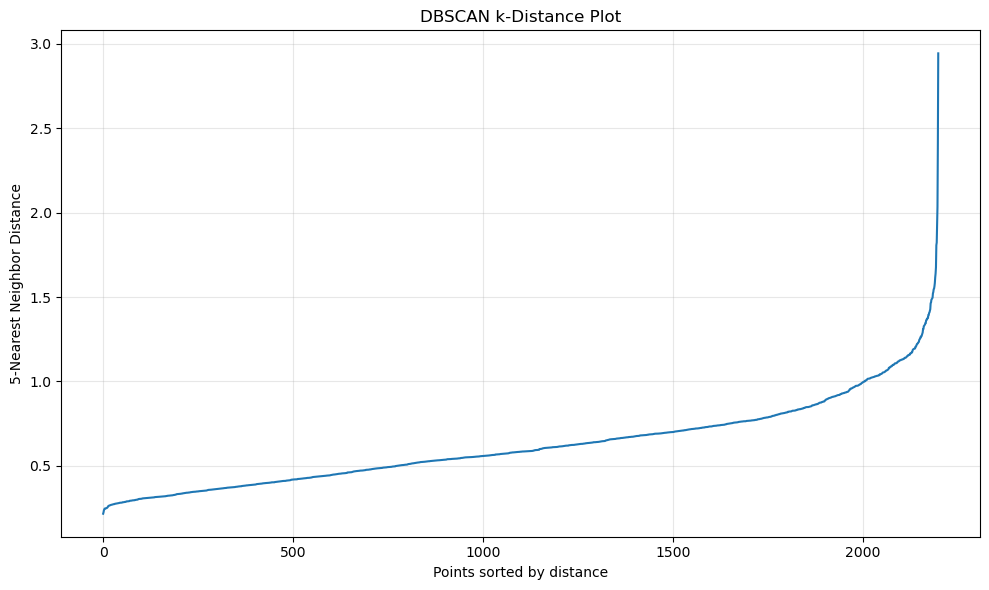

In [36]:
min_samples_value = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples_value
)

neighbors.fit(X_sf24_scaled)

distances, indices = neighbors.kneighbors(X_sf24_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel(f"{min_samples_value}-Nearest Neighbor Distance")
plt.title("DBSCAN k-Distance Plot")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
eps_values = [0.5, 0.7, 1.0, 1.2, 1.5]
min_samples_values = [5, 10, 15]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_sf24_scaled)

        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]

        n_clusters = len(set(non_noise_labels))
        n_noise = int(np.sum(labels == -1))
        noise_percentage = (n_noise / len(labels)) * 100

        # Calculate silhouette only when valid
        if (
            n_clusters >= 2
            and np.sum(non_noise_mask) > n_clusters
        ):
            score = silhouette_score(
                X_sf24_scaled[non_noise_mask],
                non_noise_labels
            )
        else:
            score = np.nan

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "number_of_clusters": n_clusters,
            "noise_points": n_noise,
            "noise_percentage": noise_percentage,
            "silhouette_score_excluding_noise": score
        })

dbscan_evaluation = pd.DataFrame(dbscan_results)

dbscan_evaluation

,eps,min_samples,number_of_clusters,noise_points,noise_percentage,silhouette_score_excluding_noise
0,0.5,5,32,1184,53.818182,0.473184
1,0.5,10,13,1528,69.454545,0.610416
2,0.5,15,8,1733,78.772727,0.654399
3,0.7,5,26,442,20.090909,0.367204
4,0.7,10,26,834,37.909091,0.504612
5,0.7,15,13,1152,52.363636,0.618198
6,1.0,5,17,95,4.318182,0.271820
7,1.0,10,10,236,10.727273,0.286438
8,1.0,15,12,272,12.363636,0.377527
9,1.2,5,3,18,0.818182,0.260427


In [38]:
os.makedirs("stage8_outputs", exist_ok=True)

dbscan_evaluation.to_csv(
    os.path.join(
        "stage8_outputs",
        "dbscan_parameter_evaluation.csv"
    ),
    index=False
)

print("DBSCAN evaluation results saved.")

DBSCAN evaluation results saved.


In [39]:
# Keep only configurations with valid silhouette scores
valid_dbscan = dbscan_evaluation.dropna(
    subset=["silhouette_score_excluding_noise"]
).copy()

if valid_dbscan.empty:
    raise ValueError(
        "No valid DBSCAN silhouette scores. "
        "Review dbscan_evaluation and adjust the parameter search."
    )

# Rank candidates by silhouette score
valid_dbscan = valid_dbscan.sort_values(
    "silhouette_score_excluding_noise",
    ascending=False
)

print("DBSCAN candidates ranked by silhouette score:")
display(valid_dbscan)

# Provisional selection: highest valid silhouette score
best_dbscan_row = valid_dbscan.iloc[0]

dbscan_eps = float(best_dbscan_row["eps"])
dbscan_min_samples = int(best_dbscan_row["min_samples"])

print("Provisional eps:", dbscan_eps)
print("Provisional min_samples:", dbscan_min_samples)
print("Number of clusters:", int(best_dbscan_row["number_of_clusters"]))
print("Noise percentage:", round(
    float(best_dbscan_row["noise_percentage"]), 2
))

DBSCAN candidates ranked by silhouette score:


,eps,min_samples,number_of_clusters,noise_points,noise_percentage,silhouette_score_excluding_noise
2,0.5,15,8,1733,78.772727,0.654399
5,0.7,15,13,1152,52.363636,0.618198
1,0.5,10,13,1528,69.454545,0.610416
4,0.7,10,26,834,37.909091,0.504612
0,0.5,5,32,1184,53.818182,0.473184
8,1.0,15,12,272,12.363636,0.377527
3,0.7,5,26,442,20.090909,0.367204
7,1.0,10,10,236,10.727273,0.286438
6,1.0,5,17,95,4.318182,0.271820
14,1.5,15,3,24,1.090909,0.261577


Provisional eps: 0.5
Provisional min_samples: 15
Number of clusters: 8
Noise percentage: 78.77


In [40]:
dbscan_final = DBSCAN(
    eps=dbscan_eps,
    min_samples=dbscan_min_samples
)

dbscan_labels = dbscan_final.fit_predict(X_sf24_scaled)

sf24_clustered["dbscan_cluster"] = dbscan_labels

print("DBSCAN cluster distribution:")
print(
    pd.Series(dbscan_labels, name="dbscan_cluster")
    .value_counts()
    .sort_index()
)

DBSCAN cluster distribution:
dbscan_cluster
-1    1733
 0      98
 1      34
 2      15
 3      17
 4      16
 5      87
 6     100
 7     100
Name: count, dtype: int64


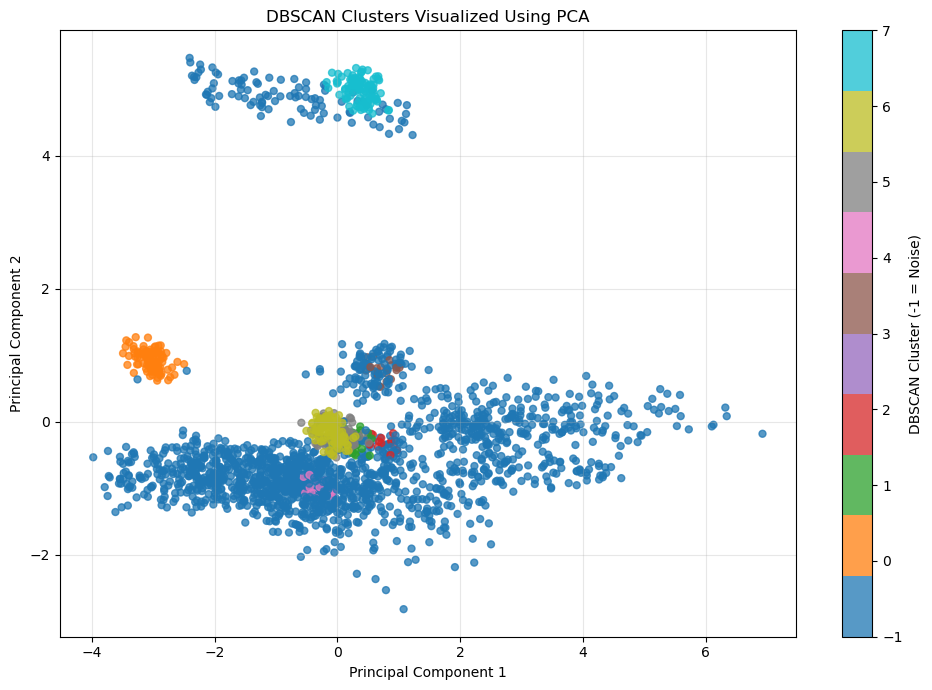

In [41]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_2d_df["PC1"],
    pca_2d_df["PC2"],
    c=dbscan_labels,
    cmap="tab10",
    s=25,
    alpha=0.75
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clusters Visualized Using PCA")
plt.colorbar(scatter, label="DBSCAN Cluster (-1 = Noise)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import silhouette_score

kmeans_labels = sf24_clustered["kmeans_cluster"].to_numpy()

# K-Means silhouette score
kmeans_silhouette = silhouette_score(
    X_sf24_scaled,
    kmeans_labels
)

# DBSCAN cluster statistics
dbscan_non_noise = dbscan_labels != -1
dbscan_non_noise_labels = dbscan_labels[dbscan_non_noise]

dbscan_cluster_count = len(set(dbscan_non_noise_labels))
dbscan_noise_count = int(np.sum(dbscan_labels == -1))

if (
    dbscan_cluster_count >= 2
    and dbscan_non_noise.sum() > dbscan_cluster_count
):
    dbscan_silhouette = silhouette_score(
        X_sf24_scaled[dbscan_non_noise],
        dbscan_non_noise_labels
    )
else:
    dbscan_silhouette = np.nan

comparison = pd.DataFrame([
    {
        "method": "K-Means",
        "number_of_clusters": len(np.unique(kmeans_labels)),
        "noise_points": 0,
        "noise_percentage": 0.0,
        "silhouette_score": kmeans_silhouette
    },
    {
        "method": "DBSCAN",
        "number_of_clusters": dbscan_cluster_count,
        "noise_points": dbscan_noise_count,
        "noise_percentage": dbscan_noise_count / len(dbscan_labels) * 100,
        "silhouette_score": dbscan_silhouette
    }
])

comparison

,method,number_of_clusters,noise_points,noise_percentage,silhouette_score
0,K-Means,3,0,0.000000,0.275211
1,DBSCAN,8,1733,78.772727,0.654399


In [43]:
profile_data = sf24_clustered.drop(
    columns=["label", "dbscan_cluster"],
    errors="ignore"
).copy()

profile_data["kmeans_cluster"] = (
    sf24_clustered["kmeans_cluster"].to_numpy()
)

kmeans_cluster_sizes = (
    profile_data["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("row_count")
)

kmeans_cluster_means = profile_data.groupby(
    "kmeans_cluster"
).mean(numeric_only=True)

kmeans_cluster_medians = profile_data.groupby(
    "kmeans_cluster"
).median(numeric_only=True)

print("Cluster sizes:")
display(kmeans_cluster_sizes.to_frame())

print("Cluster feature means:")
display(kmeans_cluster_means)

print("Cluster feature medians:")
display(kmeans_cluster_medians)

Cluster sizes:


,row_count
kmeans_cluster,
0,867
1,1133
2,200


Cluster feature means:


,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P
kmeans_cluster,,,,,,,,,,,,
0,52.161169,27.689735,25.516876,28.194925,2.591912,112.373702,2027.632176,80.415644,1.260833,3888.884143,1378.423160,56.489043
1,83.508667,37.000000,26.111698,72.701677,1.138762,146.548102,3206.612044,123.277156,2.259533,10187.973763,2188.721025,36.846425
2,87.104305,200.000000,23.240259,21.990000,0.667079,355.365000,2106.557670,91.133304,0.109960,8050.545194,2021.978222,133.375000


Cluster feature medians:


,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P
kmeans_cluster,,,,,,,,,,,,
0,56.310068,21.0,27.003155,26.0,2.722222,106.0,1708.988215,72.431691,1.041667,3800.209063,1457.069294,59.0
1,84.793524,39.0,25.701967,83.0,1.042553,160.0,2876.421953,110.231663,1.940000,9483.606532,2121.236145,35.0
2,87.004634,200.0,22.628290,24.0,0.670025,354.5,2399.428032,87.516203,0.122449,7666.015069,2081.843109,135.0


In [44]:
kmeans_crop_crosstab = pd.crosstab(
    sf24_clustered["kmeans_cluster"],
    sf24_clustered["label"],
    margins=True
)

print("K-Means cluster versus crop label:")
display(kmeans_crop_crosstab)

kmeans_crop_distribution = pd.crosstab(
    sf24_clustered["kmeans_cluster"],
    sf24_clustered["label"],
    normalize="index"
) * 100

print("Crop-label percentages within each K-Means cluster:")
display(kmeans_crop_distribution.round(2))

K-Means cluster versus crop label:


label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon,All
kmeans_cluster,,,,,,,,,,,,,,,,,,,,,
0,0,0,100,100,0,0,0,0,0,100,...,100,97,0,18,1,94,0,0,0,867
1,0,100,0,0,100,100,100,0,100,0,...,0,3,100,82,99,6,100,100,100,1133
2,100,0,0,0,0,0,0,100,0,0,...,0,0,0,0,0,0,0,0,0,200
All,100,100,100,100,100,100,100,100,100,100,...,100,100,100,100,100,100,100,100,100,2200


Crop-label percentages within each K-Means cluster:


label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
kmeans_cluster,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.00,11.53,11.53,0.00,0.00,0.00,0.0,0.00,11.53,...,11.30,11.53,11.19,0.00,2.08,0.12,10.84,0.00,0.00,0.00
1,0.0,8.83,0.00,0.00,8.83,8.83,8.83,0.0,8.83,0.00,...,0.18,0.00,0.26,8.83,7.24,8.74,0.53,8.83,8.83,8.83
2,50.0,0.00,0.00,0.00,0.00,0.00,0.00,50.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [45]:
purity_rows = []

for cluster_id, group in sf24_clustered.groupby("kmeans_cluster"):
    label_counts = group["label"].value_counts()

    dominant_label = label_counts.index[0]
    dominant_count = int(label_counts.iloc[0])
    total_count = len(group)

    purity_rows.append({
        "kmeans_cluster": cluster_id,
        "row_count": total_count,
        "dominant_crop_label": dominant_label,
        "dominant_label_count": dominant_count,
        "purity": dominant_count / total_count
    })

kmeans_purity = pd.DataFrame(purity_rows)

display(kmeans_purity)

,kmeans_cluster,row_count,dominant_crop_label,dominant_label_count,purity
0,0,867,chickpea,100,0.115340
1,1,1133,rice,100,0.088261
2,2,200,grapes,100,0.500000


In [46]:
OUTPUT_DIR = "stage8_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Cluster assignments
sf24_clustered.to_csv(
    os.path.join(OUTPUT_DIR, "sf24_cluster_assignments.csv"),
    index=False
)

# K-Means evaluation
kmeans_evaluation.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_evaluation.csv"),
    index=False
)

# DBSCAN evaluation and comparison
dbscan_evaluation.to_csv(
    os.path.join(OUTPUT_DIR, "dbscan_parameter_evaluation.csv"),
    index=False
)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_vs_dbscan_comparison.csv"),
    index=False
)

# K-Means profiles
kmeans_cluster_sizes.to_frame().to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_sizes.csv")
)

kmeans_cluster_means.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_means.csv")
)

kmeans_cluster_medians.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_medians.csv")
)

# Crop-label analysis
kmeans_crop_crosstab.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_crop_crosstab.csv")
)

kmeans_crop_distribution.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_crop_percentages.csv")
)

kmeans_purity.to_csv(
    os.path.join(OUTPUT_DIR, "kmeans_cluster_purity.csv"),
    index=False
)

dbscan_crop_crosstab.to_csv(
    os.path.join(OUTPUT_DIR, "dbscan_cluster_crop_crosstab.csv")
)

# PCA coordinates and cluster assignments
pca_output = pca_2d_df.copy()
pca_output["kmeans_cluster"] = kmeans_labels
pca_output["dbscan_cluster"] = dbscan_labels

pca_output.to_csv(
    os.path.join(OUTPUT_DIR, "pca_cluster_visualization_data.csv"),
    index=False
)

print("Stage 8 output files saved:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

NameError: name 'dbscan_crop_crosstab' is not defined

In [47]:
assert len(sf24_clustered) == len(sf24)
assert len(sf24_clustered["kmeans_cluster"]) == len(sf24)
assert len(sf24_clustered["dbscan_cluster"]) == len(sf24)

assert sf24_clustered["kmeans_cluster"].notna().all()
assert sf24_clustered["dbscan_cluster"].notna().all()

assert set(sf24_clustered["kmeans_cluster"].unique()) == set(
    np.unique(kmeans_labels)
)

print("Final validation passed.")
print("Dataset rows:", len(sf24_clustered))
print("Original features:", X_sf24.shape[1])
print("K-Means clusters:", sf24_clustered["kmeans_cluster"].nunique())
print(
    "DBSCAN clusters excluding noise:",
    len(set(dbscan_labels) - {-1})
)
print("DBSCAN noise points:", int(np.sum(dbscan_labels == -1)))
print("Label used to create clusters: No")

Final validation passed.
Dataset rows: 2200
Original features: 12
K-Means clusters: 3
DBSCAN clusters excluding noise: 8
DBSCAN noise points: 1733
Label used to create clusters: No


In [48]:
stage8_summary = pd.DataFrame([
    {
        "item": "Dataset",
        "result": "crop_recommendation_selected"
    },
    {
        "item": "Rows",
        "result": len(sf24)
    },
    {
        "item": "Features used for clustering",
        "result": X_sf24.shape[1]
    },
    {
        "item": "K-Means cluster count",
        "result": sf24_clustered["kmeans_cluster"].nunique()
    },
    {
        "item": "DBSCAN cluster count excluding noise",
        "result": len(set(dbscan_labels) - {-1})
    },
    {
        "item": "DBSCAN noise points",
        "result": int(np.sum(dbscan_labels == -1))
    },
    {
        "item": "K-Means silhouette score",
        "result": round(float(kmeans_silhouette), 4)
    },
    {
        "item": "DBSCAN silhouette score excluding noise",
        "result": (
            round(float(dbscan_silhouette), 4)
            if pd.notna(dbscan_silhouette)
            else "Not available"
        )
    }
])

display(stage8_summary)

stage8_summary.to_csv(
    os.path.join(OUTPUT_DIR, "stage8_summary.csv"),
    index=False
)

print("Stage 8 summary saved.")

,item,result
0,Dataset,crop_recommendation_selected
1,Rows,2200
2,Features used for clustering,12
3,K-Means cluster count,3
4,DBSCAN cluster count excluding noise,8
5,DBSCAN noise points,1733
6,K-Means silhouette score,0.2752
7,DBSCAN silhouette score excluding noise,0.6544


Stage 8 summary saved.
